# Adversarial Class-Mean Reconstruction

A trained classifier leaks more than its predictions: its decision function encodes the central tendency of each training class. This notebook asks whether an attacker can recover a sample that is close to the **training class mean** while only having access to the model.

For a target class $c$ we solve

$$
x_c^* = \arg\min_{x \in [0,1]^{C \times H \times W}}
\underbrace{\mathrm{CE}(f(x), c)}_{\text{class evidence}}
+ \lambda \underbrace{\lVert x - \mu_{\mathrm{global}} \rVert_2^2}_{\text{data-domain prior}},
$$

where $\mu_{\mathrm{global}}$ is the **global** pixel mean of the dataset, not the mean of class $c$. The class mean $\mu_c$ is never passed to the optimizer. It is computed separately and used exclusively to score the attack.

The result is an **adversarial example**: it is optimized against the model rather than sampled from the data distribution, yet it is pulled towards the centre of the target class.


## Setup

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
import torch.nn.functional as functional
from shared import setup
from torch.utils.data import DataLoader

from privacy_and_grokking.artifacts.cache import get_artifact_path, get_training_config
from privacy_and_grokking.artifacts.local import get_plots_dir
from privacy_and_grokking.utils.logger import Logger

D:\privacy-and-grokking\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
setup()
_ = Logger().setup()

{"log_file": "C:\\Users\\Qunor\\AppData\\Local\\Temp\\2026-11-02T12-50-40_hx_a1hq8.log", "event": "Logger initialized", "timestamp": "2026-11-02T11:50:40.272572Z", "level": "info"}


## Model and Data

We use a cached MNIST MLP checkpoint. It was trained on a masked 50% split of MNIST (24,950 natural training images) and reaches about 97.9% test accuracy. The configuration and checkpoint are resolved through the project cache; `get_artifact_path` falls back to the MLflow server if the local cache is cold.


In [3]:
RUN_ID = "088b42f7979f4c769bd6256d29b08ee0"
CHECKPOINT_STEP = 150_000
CLASSES = list(range(10))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Fixed before looking at the true class means.  The prior weight controls how
# strongly the generated sample is pulled towards the global data mean.
PRIOR_WEIGHT = 1e-3
NUM_ITERATIONS = 2_000
LEARNING_RATE = 0.05
RECORD_EVERY = 50

In [4]:
config = get_training_config(RUN_ID)
data = config.data()

model = config.model(input_dim=data.input_shape, num_classes=data.num_classes)
checkpoint_path = get_artifact_path(RUN_ID, f"checkpoints/{CHECKPOINT_STEP}/model.pth")
model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))
model.to(DEVICE).eval()

norm_mean = torch.tensor(data.normalization.mean, device=DEVICE).view(1, -1, 1, 1)
norm_std = torch.tensor(data.normalization.std, device=DEVICE).view(1, -1, 1, 1)


def normalize(images: torch.Tensor) -> torch.Tensor:
    """Apply the dataset normalization expected by the model."""
    return (images - norm_mean) / norm_std

In [5]:
correct = 0
total = 0
with torch.no_grad():
    for images, labels in DataLoader(data.test, batch_size=1024):
        predictions = model(normalize(images.to(DEVICE))).argmax(dim=1)
        correct += (predictions.cpu() == labels).sum().item()
        total += labels.numel()

print(f"Test accuracy: {correct / total:.4f}")
print(f"Training samples: {len(data.train)}")

Test accuracy: 0.9792
Training samples: 24950


## Ground Truth for Evaluation Only

> **Threat model.** Everything in this section is computed separately from the attack. The class means and the distance statistics are never passed to the optimizer; they only provide the reference against which the reconstruction is scored.

We compute the true class means $\mu_c = \frac{1}{n_c}\sum_{i:y_i=c} x_i$ from the natural training images, together with the distribution of distances $\lVert x_i - \mu_{y_i}\rVert_2$ of individual training samples to their own class mean. The latter tells us what "close to the mean" means for a real member of the class.


In [6]:
train_batches = list(DataLoader(data.train, batch_size=2048))
train_images = torch.cat([images for images, _ in train_batches])
train_labels = torch.cat([labels for _, labels in train_batches])

class_means = torch.stack([train_images[train_labels == c].mean(dim=0) for c in CLASSES])

# Subsample the per-class distance distribution for plotting.  The class mean
# itself is always computed from all available samples.
MAX_DISTANCE_SAMPLES_PER_CLASS = 1_000
sample_distances = []
for c in CLASSES:
    indices = torch.nonzero(train_labels == c, as_tuple=False).squeeze(1)
    stride = max(1, len(indices) // MAX_DISTANCE_SAMPLES_PER_CLASS)
    selected = indices[::stride]
    sample_distances.append(
        (train_images[selected].flatten(1) - class_means[c].flatten()).norm(dim=1)
    )

with torch.no_grad():
    mean_confidences = functional.softmax(model(normalize(class_means.to(DEVICE))), dim=1)

summary = pl.DataFrame(
    {
        "class": CLASSES,
        "train_samples": [int((train_labels == c).sum()) for c in CLASSES],
        "mean_norm": [float(class_means[c].norm()) for c in CLASSES],
        "confidence_on_mean": [float(mean_confidences[c, c]) for c in CLASSES],
        "median_sample_distance": [float(d.median()) for d in sample_distances],
    }
)
summary

class,train_samples,mean_norm,confidence_on_mean,median_sample_distance
i64,i64,f64,f64,f64
0,2495,8.216979,1.0,6.968513
1,2495,5.394528,0.70755,4.405355
2,2495,7.060485,0.999998,7.038191
3,2495,7.099642,1.0,6.593375
4,2495,6.328974,1.0,6.18263
5,2495,6.130857,0.998205,6.714424
6,2495,7.026048,1.0,6.261262
7,2495,6.303151,0.999963,5.852093
8,2495,7.452576,0.999999,6.551228


## Attack

The attacker knows the model weights, the input normalization, and the global pixel mean. The latter is a public dataset constant, not the mean of any individual class. The only class-specific signal comes from the model's cross-entropy on the target label.

For a linear class-conditional Gaussian model this objective has a useful interpretation: the MAP estimate under a Gaussian prior centred at the global mean lies on the line from the global mean towards the class mean, and with the correct prior strength it coincides with the class mean. For a deep network the same prior acts as a regularizer that prevents the optimizer from running off to a high-confidence, high-frequency corner of the input cube.


In [7]:
# Public MNIST constant.  It is the global pixel mean, not the mean of any
# individual class, so the attacker may know it without learning the target.
GLOBAL_MEAN = float(torch.tensor(data.normalization.mean).mean())
print(f"Global pixel mean used by the prior: {GLOBAL_MEAN:.4f}")

Global pixel mean used by the prior: 0.1307


In [8]:
def generate_adversarial_example(
    target_class: int,
    prior_weight: float = PRIOR_WEIGHT,
    num_iterations: int = NUM_ITERATIONS,
    learning_rate: float = LEARNING_RATE,
    seed: int = 0,
    record_every: int = RECORD_EVERY,
) -> dict:
    """Generate a confident sample of ``target_class`` without class-mean access.

    The objective is

        CE(f(x), target_class) + prior_weight * ||x - global_mean||_2^2

    subject to ``x in [0, 1]``.  The global mean is a public dataset constant,
    not the target class mean.  The true class mean is only used afterwards to
    score the result.
    """
    generator = torch.Generator().manual_seed(seed)
    x = torch.rand((1, *data.input_shape), generator=generator).to(DEVICE)
    x.requires_grad_(True)

    optimizer = torch.optim.Adam([x], lr=learning_rate)
    target = torch.tensor([target_class], device=DEVICE)

    history = []
    for iteration in range(num_iterations):
        optimizer.zero_grad()
        logits = model(normalize(x))
        ce_loss = functional.cross_entropy(logits, target)
        prior_loss = ((x - GLOBAL_MEAN) ** 2).sum()
        loss = ce_loss + prior_weight * prior_loss
        loss.backward()
        optimizer.step()

        with torch.no_grad():
            x.clamp_(0.0, 1.0)

        if iteration % record_every == 0 or iteration == num_iterations - 1:
            with torch.no_grad():
                probability = functional.softmax(model(normalize(x)), dim=1)[0, target_class].item()
                # Evaluation only: the optimizer never sees this quantity.
                distance = (x[0].cpu() - class_means[target_class]).norm().item()
            history.append(
                {
                    "iteration": iteration,
                    "loss": loss.item(),
                    "confidence": probability,
                    "distance_to_true_mean": distance,
                }
            )

    with torch.no_grad():
        final_probability = functional.softmax(model(normalize(x)), dim=1)[0, target_class].item()
        final_distance = (x[0].cpu() - class_means[target_class]).norm().item()

    # Nearest natural training sample of the target class, for reference.
    class_indices = torch.nonzero(train_labels == target_class, as_tuple=False).squeeze(1)
    class_images = train_images[class_indices].flatten(1).to(DEVICE)
    distances = (class_images - x.detach().flatten()).norm(dim=1)
    nearest_position = int(distances.argmin().item())

    return {
        "image": x.detach().cpu(),
        "confidence": final_probability,
        "distance_to_true_mean": final_distance,
        "nearest_train_index": int(class_indices[nearest_position].item()),
        "nearest_train_distance": float(distances[nearest_position].item()),
        "history": pl.DataFrame(history),
    }

In [9]:
results = {}
for c in CLASSES:
    print(f"Generating class {c} ...", end=" ")
    results[c] = generate_adversarial_example(c, seed=c)
    print(
        f"confidence={results[c]['confidence']:.4f}  "
        f"distance={results[c]['distance_to_true_mean']:.2f}"
    )

Generating class 0 ... 

confidence=1.0000  distance=6.35
Generating class 1 ... 

confidence=1.0000  distance=5.72
Generating class 2 ... 

confidence=1.0000  distance=4.80
Generating class 3 ... 

confidence=1.0000  distance=5.68
Generating class 4 ... 

confidence=1.0000  distance=4.47
Generating class 5 ... 

confidence=0.9999  distance=4.09
Generating class 6 ... 

confidence=1.0000  distance=4.78
Generating class 7 ... 

confidence=1.0000  distance=5.53
Generating class 8 ... 

confidence=1.0000  distance=5.91
Generating class 9 ... 

confidence=0.9999  distance=5.66


## Results

In [10]:
rows = []
for c in CLASSES:
    result = results[c]
    distances = sample_distances[c]
    rows.append(
        {
            "class": c,
            "confidence": result["confidence"],
            "dist_to_true_mean": result["distance_to_true_mean"],
            "train_dist_mean": float(distances.mean()),
            "train_dist_median": float(distances.median()),
            "train_dist_p90": float(distances.quantile(0.9)),
            "dist_to_nearest_train": result["nearest_train_distance"],
            "nearest_train_index": result["nearest_train_index"],
        }
    )

results_df = (
    pl.DataFrame(rows)
    .with_columns(
        (pl.col("dist_to_true_mean") / pl.col("train_dist_median")).alias("relative_to_median")
    )
    .sort("class")
)

print(f"Mean adversarial distance: {results_df['dist_to_true_mean'].mean():.2f}")
print(f"Mean median training distance: {results_df['train_dist_median'].mean():.2f}")
print(
    "Classes closer than a typical training sample: "
    f"{(results_df['relative_to_median'] < 1).sum()} / {len(CLASSES)}"
)
results_df

Mean adversarial distance: 5.30
Mean median training distance: 6.25
Classes closer than a typical training sample: 9 / 10


class,confidence,dist_to_true_mean,train_dist_mean,train_dist_median,train_dist_p90,dist_to_nearest_train,nearest_train_index,relative_to_median
i64,f64,f64,f64,f64,f64,f64,i64,f64
0,1.0,6.353112,7.023613,6.968513,8.083592,5.979377,716,0.911688
1,0.999999,5.716576,4.692595,4.405355,6.107535,6.19286,2821,1.297643
2,1.0,4.795951,7.092394,7.038191,8.039343,5.937552,6443,0.681418
3,0.999992,5.680506,6.705477,6.593375,7.925088,6.111966,8069,0.861548
4,1.0,4.473556,6.338395,6.18263,7.500491,5.926007,10678,0.723568
5,0.999903,4.087356,6.842826,6.714424,8.038204,5.513997,14635,0.608743
6,1.0,4.779482,6.491553,6.261262,7.833549,5.677868,17448,0.763342
7,0.999996,5.532303,6.028559,5.852093,7.302088,6.09577,19353,0.945355
8,0.999992,5.914267,6.702588,6.551228,7.936191,6.152314,22247,0.902772


### Qualitative comparison

The first row shows the mean-free adversarial example, the second the true training class mean, the third the nearest natural training sample, and the fourth the absolute difference between the adversarial example and the mean. The adversarial images are low-contrast prototypes rather than realistic digits; the point is their position relative to the class mean, not their perceptual quality.


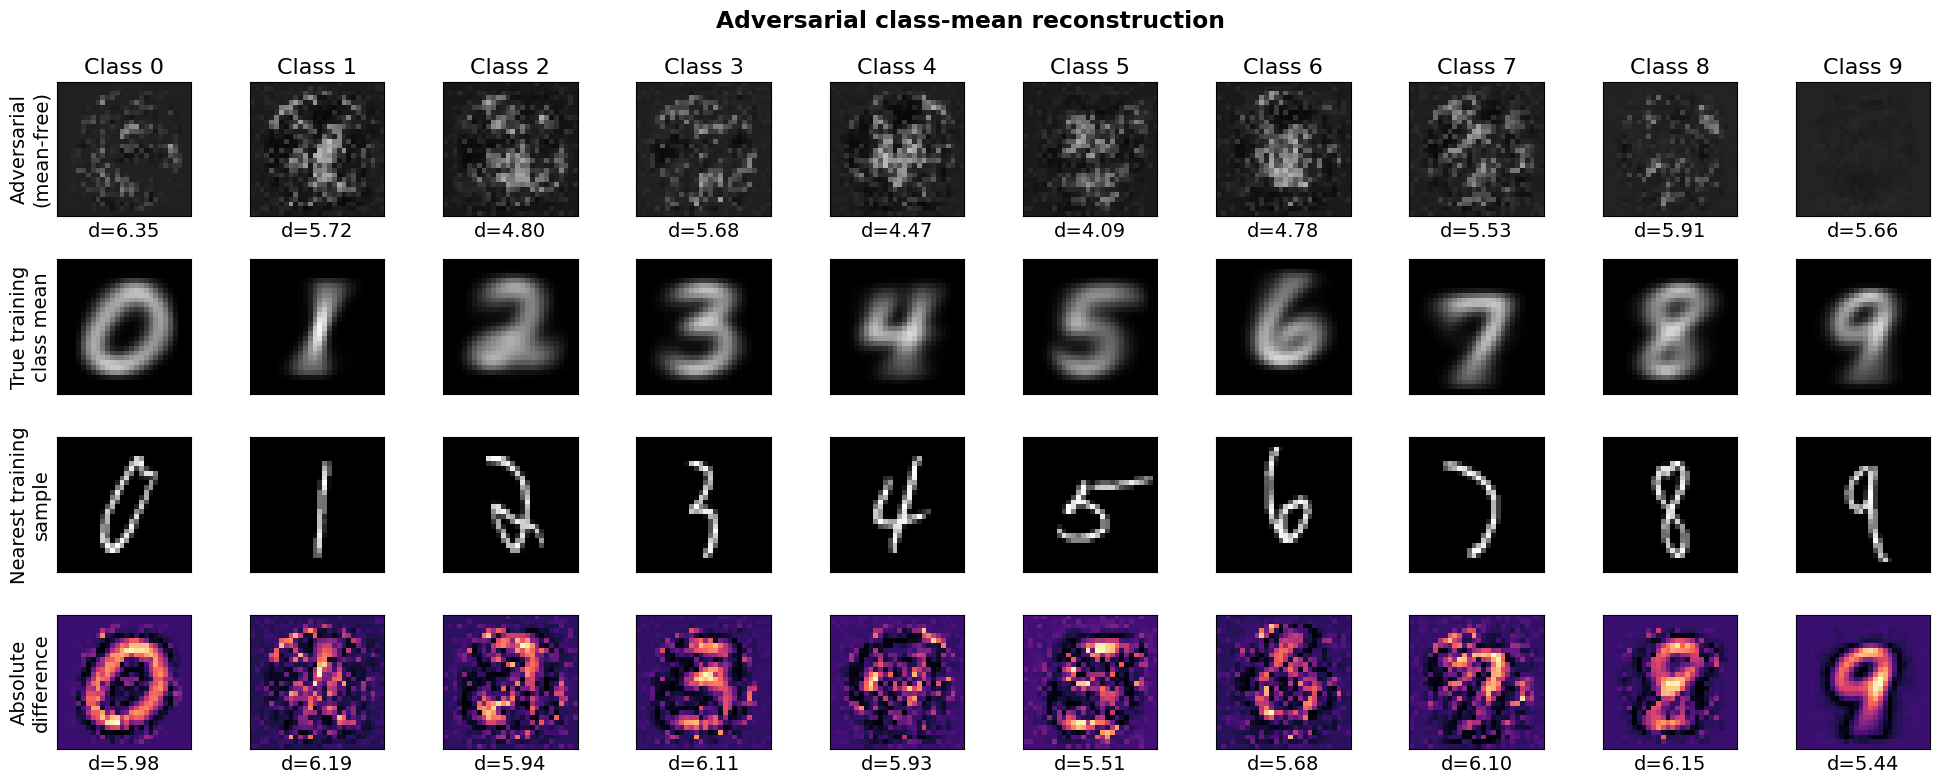

In [11]:
PLOTS = get_plots_dir()
PLOTS.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(4, len(CLASSES), figsize=(2.0 * len(CLASSES), 8.0))
row_labels = [
    "Adversarial\n(mean-free)",
    "True training\nclass mean",
    "Nearest training\nsample",
    "Absolute\ndifference",
]
for c in CLASSES:
    adversarial = results[c]["image"][0, 0].numpy()
    mean = class_means[c, 0].numpy()
    nearest = train_images[results[c]["nearest_train_index"], 0].numpy()
    axes[0, c].imshow(adversarial, cmap="gray", vmin=0, vmax=1)
    axes[0, c].set_title(f"Class {c}")
    axes[1, c].imshow(mean, cmap="gray", vmin=0, vmax=1)
    axes[2, c].imshow(nearest, cmap="gray", vmin=0, vmax=1)
    axes[3, c].imshow(np.abs(adversarial - mean), cmap="magma")
    for row in range(4):
        axes[row, c].set_xticks([])
        axes[row, c].set_yticks([])
    axes[0, c].set_xlabel(f"d={results[c]['distance_to_true_mean']:.2f}")
    axes[3, c].set_xlabel(f"d={results[c]['nearest_train_distance']:.2f}")
for row, label in enumerate(row_labels):
    axes[row, 0].set_ylabel(label)
fig.suptitle("Adversarial class-mean reconstruction", fontweight="bold")
fig.tight_layout()

fig.savefig(
    PLOTS / f"adversarial_class_mean_grid_{date.today()}.pdf",
    format="pdf",
    bbox_inches="tight",
)
fig.savefig(
    PLOTS / f"adversarial_class_mean_grid_{date.today()}.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Quantitative comparison

Panel (a) compares the adversarial distance to the true class mean with the distribution of distances of natural training samples to their own class mean. Panel (b) normalizes by the median training distance: values below one mean that the adversarial example is closer to the class mean than a typical training sample. Panel (c) shows the optimization trajectory; the distance to the true mean is recorded for evaluation only and is never part of the loss.


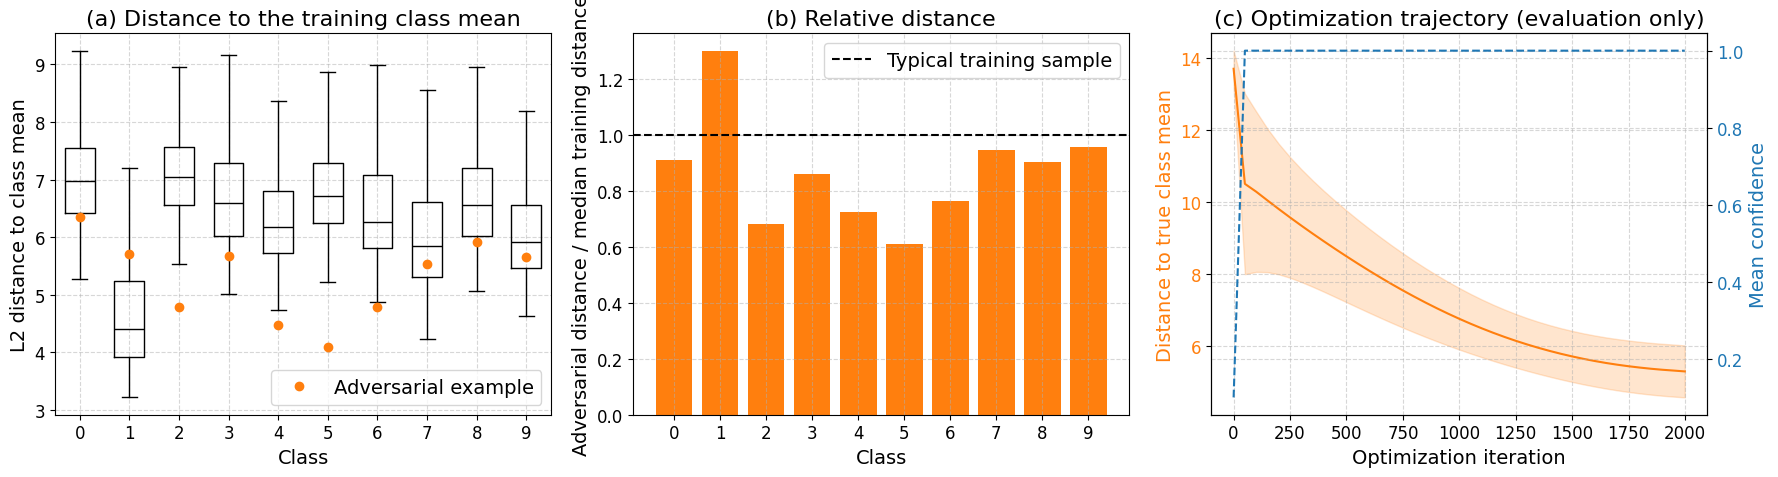

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].boxplot(
    [d.numpy() for d in sample_distances],
    positions=CLASSES,
    widths=0.6,
    showfliers=False,
    medianprops={"color": "black"},
)
axes[0].plot(
    CLASSES,
    [results[c]["distance_to_true_mean"] for c in CLASSES],
    marker="o",
    linestyle="",
    color="tab:orange",
    label="Adversarial example",
    zorder=3,
)
axes[0].set_xlabel("Class")
axes[0].set_ylabel("L2 distance to class mean")
axes[0].set_title("(a) Distance to the training class mean")
axes[0].legend()

relative = results_df["relative_to_median"].to_numpy()
axes[1].bar(CLASSES, relative, color="tab:orange")
axes[1].axhline(1.0, color="black", linestyle="--", label="Typical training sample")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Adversarial distance / median training distance")
axes[1].set_title("(b) Relative distance")
axes[1].set_xticks(CLASSES)
axes[1].legend()

history_df = pl.concat(
    [results[c]["history"].with_columns(pl.lit(c).alias("class")) for c in CLASSES]
)
trajectory = (
    history_df.group_by("iteration")
    .agg(
        pl.col("distance_to_true_mean").mean().alias("distance_mean"),
        pl.col("distance_to_true_mean").std().alias("distance_std"),
        pl.col("confidence").mean().alias("confidence_mean"),
    )
    .sort("iteration")
)
iterations = trajectory["iteration"].to_numpy()
distance_mean = trajectory["distance_mean"].to_numpy()
distance_std = trajectory["distance_std"].fill_null(0.0).to_numpy()
axes[2].plot(iterations, distance_mean, color="tab:orange", label="Mean distance")
axes[2].fill_between(
    iterations,
    distance_mean - distance_std,
    distance_mean + distance_std,
    color="tab:orange",
    alpha=0.2,
)
axes[2].set_xlabel("Optimization iteration")
axes[2].set_ylabel("Distance to true class mean", color="tab:orange")
axes[2].tick_params(axis="y", labelcolor="tab:orange")
axes[2].set_title("(c) Optimization trajectory (evaluation only)")
twin = axes[2].twinx()
twin.plot(iterations, trajectory["confidence_mean"], color="tab:blue", linestyle="--")
twin.set_ylabel("Mean confidence", color="tab:blue")
twin.tick_params(axis="y", labelcolor="tab:blue")

fig.tight_layout()
fig.savefig(
    PLOTS / f"adversarial_class_mean_metrics_{date.today()}.pdf",
    format="pdf",
    bbox_inches="tight",
)
fig.savefig(
    PLOTS / f"adversarial_class_mean_metrics_{date.today()}.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### How large is the distance?

The pixel-space distance is only meaningful relative to reference scales. The following cell computes the split-half noise floor of the class mean, the distance between different class means, and the distance of a $k$-sample average to the full class mean. These references separate "closer than a random sample" from "actually reconstructed the mean".


In [13]:
# Reference scales for interpreting the pixel-space distance.
global_mean = train_images.mean(dim=0, keepdim=True)
global_to_class = torch.stack([(class_means[c] - global_mean).norm() for c in CLASSES])

pairwise = torch.cdist(class_means.flatten(1), class_means.flatten(1))
mean_pairwise_class_distance = pairwise[~torch.eye(len(CLASSES), dtype=torch.bool)].mean()

# Split-half noise floor: two independent estimates of the same class mean.
generator = torch.Generator().manual_seed(0)
split_half = []
for c in CLASSES:
    indices = torch.nonzero(train_labels == c, as_tuple=False).squeeze(1)
    permutation = torch.randperm(len(indices), generator=generator)
    first = indices[permutation[: len(indices) // 2]]
    second = indices[permutation[len(indices) // 2 :]]
    split_half.append((train_images[first].mean(0) - train_images[second].mean(0)).norm())
split_half = torch.stack(split_half)

# Distance of a k-sample average to the full class mean.
k_values = [1, 2, 5, 10, 25, 50, 100, 250, 500, 1000]
k_distances = {}
for k in k_values:
    values = []
    for c in CLASSES:
        indices = torch.nonzero(train_labels == c, as_tuple=False).squeeze(1)
        for _ in range(5):
            permutation = torch.randperm(len(indices), generator=generator)
            values.append((train_images[indices[permutation[:k]]].mean(0) - class_means[c]).norm())
    k_distances[k] = float(torch.stack(values).mean())

scale_df = pl.DataFrame(
    {
        "reference": [
            "Adversarial distance to class mean",
            "Median training sample to class mean",
            "Global mean to class mean",
            "Mean pairwise class-mean distance",
            "Split-half class-mean distance",
            *[f"{k}-sample average to class mean" for k in k_values],
        ],
        "distance": [
            float(results_df["dist_to_true_mean"].mean()),
            float(results_df["train_dist_median"].mean()),
            float(global_to_class.mean()),
            float(mean_pairwise_class_distance),
            float(split_half.mean()),
            *[k_distances[k] for k in k_values],
        ],
    }
)
scale_df

reference,distance
str,f64
"""Adversarial distance to class …",5.299178
"""Median training sample to clas…",6.24792
"""Global mean to class mean""",3.180821
"""Mean pairwise class-mean dista…",4.754434
"""Split-half class-mean distance""",0.247798
…,…
"""50-sample average to class mea…",0.886868
"""100-sample average to class me…",0.608418
"""250-sample average to class me…",0.392002


## Interpretation

The attack never receives $\mu_c$. It only minimizes the target-class cross-entropy plus a prior towards the global pixel mean. Nevertheless, the generated samples land closer to the true class means than a typical training sample for most classes (the mean relative distance is below one, and 9 of 10 classes are below the median training distance in the run shown here).

This is a weak statement: the absolute distance remains large compared with the split-half noise floor of the mean, as the scale table above shows. The generated example is a confident point in the class region, not a precise reconstruction of the class mean.

The true class means are themselves confidently classified by the model (class 1 is the exception, with a confidence of about 0.71). This is the leak the attack exploits: the model's decision region contains the class mean, so an input optimized for class evidence is naturally pulled towards the centre of the class.

Limitations:

- Pixel-space L2 distance is only one notion of closeness. A stronger image prior (TV, a generative model, or a low-resolution parameterization) would produce more realistic samples, but it is not required for the distance argument.
- The prior weight is a fixed hyperparameter. It was chosen before looking at the true class means; selecting it with the true means would violate the threat model.
- The reconstruction quality depends on model calibration and on how much the model has memorized the training distribution.
- A more direct attack would estimate $\mu_c$ from a public proxy split, match penultimate features instead of pixels, or average many diverse reconstructions.

The same mechanism underlies the distance-to-class-mean membership inference scores in the canary-selection notebooks: a model that is accurate on class means leaks a summary of the training distribution.
